In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

La matriz de incidencia $H$ del grafo PERT tiene una fila por arco (actividades y ficticias) y una columna por nodo, con −1 en el nodo origen del arco y +1 en el destino. Cada ruta es una cadena de arcos del nodo inicial al final. Considere el proyecto cuyo cuadro se adjunta.

In [3]:
pregunta_1 = "1. Dibuje el grafo PERT numerado y escriba la matriz de incidencia H (incluyendo las ficticias).  "
pregunta_2 = "2. Construya la matriz de rutas R *con* las ficticias (duración 0) y compruebe que R·H = 0 salvo en las columnas del nodo inicial y del final. ¿Por qué?  "
pregunta_3 = "3. Elija un vector y con un valor entero por nodo interior (0 en el inicial y el final) y defina la perturbación δ = H·y de las duraciones de los arcos. Compruebe que todas las rutas cambian de duración en la misma cantidad y que τ no cambia. Interprételo: ¿qué se ha hecho con los «tiempos de los nodos»?  "
pregunta_4 = "4. ¿Qué dimensión tiene el espacio de perturbaciones que dejan invariantes todas las duraciones de ruta? ¿Qué significa para la identificación de duraciones a partir de observaciones de rutas?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT numerado y escriba la matriz de incidencia H (incluyendo las ficticias).  

2. Construya la matriz de rutas R *con* las ficticias (duración 0) y compruebe que R·H = 0 salvo en las columnas del nodo inicial y del final. ¿Por qué?  

3. Elija un vector y con un valor entero por nodo interior (0 en el inicial y el final) y defina la perturbación δ = H·y de las duraciones de los arcos. Compruebe que todas las rutas cambian de duración en la misma cantidad y que τ no cambia. Interprételo: ¿qué se ha hecho con los «tiempos de los nodos»?  

4. ¿Qué dimensión tiene el espacio de perturbaciones que dejan invariantes todas las duraciones de ruta? ¿Qué significa para la identificación de duraciones a partir de observaciones de rutas?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 7       ),
    ('B'     , '---'      , 4       ),
    ('C'     , 'A,B'      , 6       ),
    ('D'     , 'C'        , 7       ),
    ('E'     , 'D'        , 6       ),
    ('F'     , 'D'        , 8       ),
    ('G'     , 'E,F'      , 6       ),
    ('H'     , 'G'        , 4       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,7
B,---,4
C,"A,B",6
D,C,7
E,D,6
F,D,8
G,"E,F",6
H,G,4


# Resolución

In [5]:
def bmatrix(a, dec=0):
    """Matriz LaTeX (bmatrix) a partir de un DataFrame o array."""
    a = np.asarray(getattr(a, 'values', a), dtype=float)
    if a.ndim == 1:
        a = a.reshape(-1, 1)
    filas = [' & '.join(f'{x:.{dec}f}' for x in fila) + r'\\' for fila in a]
    return r'\begin{bmatrix}' + '\n' + '\n'.join(filas) + '\n' + r'\end{bmatrix}'

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT numerado y escriba la matriz de incidencia H (incluyendo las ficticias).  

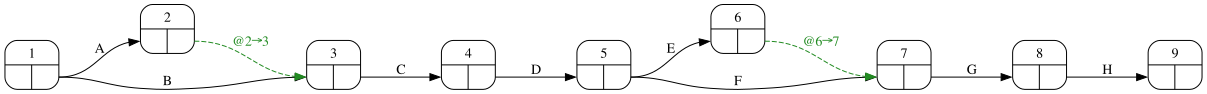

In [8]:
#| fig-cap: "Grafo PERT numerado"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)

In [9]:
#| tbl-cap: "Matriz de incidencia H (arcos × nodos)"
#| label: tbl-H
H = proyecto.incidence_matrix()
H

,1,2,3,4,5,6,7,8,9
@2→3,0,-1,1,0,0,0,0,0,0
@6→7,0,0,0,0,0,-1,1,0,0
A,-1,1,0,0,0,0,0,0,0
B,-1,0,1,0,0,0,0,0,0
C,0,0,-1,1,0,0,0,0,0
D,0,0,0,-1,1,0,0,0,0
E,0,0,0,0,-1,1,0,0,0
F,0,0,0,0,-1,0,1,0,0
G,0,0,0,0,0,0,-1,1,0
H,0,0,0,0,0,0,0,-1,1


## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Construya la matriz de rutas R *con* las ficticias (duración 0) y compruebe que R·H = 0 salvo en las columnas del nodo inicial y del final. ¿Por qué?  

In [11]:
R = proyecto.path_matrix(dummies=True)[H.index]
RH = R @ H
display(RH)
interiores = H.columns[1:-1]
Markdown(f'R·H es cero en las columnas interiores: {bool((RH[interiores] == 0).all().all())}; en la columna del nodo inicial vale {int(RH.iloc[0, 0])} y en la del final {int(RH.iloc[0, -1])} para todas las rutas.')

,1,2,3,4,5,6,7,8,9
Route_1,-1,0,0,0,0,0,0,0,1
Route_2,-1,0,0,0,0,0,0,0,1
Route_3,-1,0,0,0,0,0,0,0,1
Route_4,-1,0,0,0,0,0,0,0,1


R·H es cero en las columnas interiores: True; en la columna del nodo inicial vale -1 y en la del final 1 para todas las rutas.

Una ruta entra y sale de cada nodo interior exactamente una vez, así que la suma de sus entradas de incidencia es +1 − 1 = 0; sólo sale del inicial (−1) y sólo entra en el final (+1).

## Apartado 3

In [12]:
display(Markdown(pregunta_3))

3. Elija un vector y con un valor entero por nodo interior (0 en el inicial y el final) y defina la perturbación δ = H·y de las duraciones de los arcos. Compruebe que todas las rutas cambian de duración en la misma cantidad y que τ no cambia. Interprételo: ¿qué se ha hecho con los «tiempos de los nodos»?  

In [13]:
y_interior = {
    '2': -1,
    '3': 0,
    '4': -2,
    '5': -1,
    '6': -2,
    '7': 0,
    '8': -2,
}
y = pd.Series(0, index=H.columns, dtype=int)
for nodo, valor in y_interior.items():
    y[nodo] = valor
delta = H @ y
t = pd.Series({a: (datos_proyecto.loc[a, 'duration'] if not a.startswith('@') else 0) for a in H.index})
t_perturbado = t + delta
pd.DataFrame({'t': t, 'δ = H·y': delta, 't + δ': t_perturbado}).T

,@2→3,@6→7,A,B,C,D,E,F,G,H
t,0,0,7,4,6,7,6,8,6,4
δ = H·y,1,2,-1,0,-2,1,-1,1,-2,2
t + δ,1,2,6,4,4,8,5,9,4,6


In [14]:
Rt, Rt2 = R @ t, R @ t_perturbado
display(pd.DataFrame({'R·t': Rt, 'R·(t+δ)': Rt2, 'diferencia': Rt2 - Rt}))
Markdown(f'τ = {float(Rt.max()):.0f} antes y {float(Rt2.max()):.0f} después: las duraciones de todas las rutas cambian en {int((Rt2 - Rt).iloc[0])} (= y_final − y_inicial = 0), así que τ es invariante.')

,R·t,R·(t+δ),diferencia
Route_1,36,36,0
Route_2,38,38,0
Route_3,33,33,0
Route_4,35,35,0


τ = 38 antes y 38 después: las duraciones de todas las rutas cambian en 0 (= y_final − y_inicial = 0), así que τ es invariante.

δ = H·y añade a cada arco la diferencia de «potencial» entre su destino y su origen. Es lo mismo que mover el reloj de cada nodo: si al nodo j se le suma y_j a su tiempo, los arcos que llegan a j parecen y_j más largos y los que salen y_j más cortos, y a lo largo de cualquier ruta cerrada entre inicio y final todo se cancela. (Algunas duraciones perturbadas pueden salir negativas: es un ejercicio algebraico, no un calendario.)

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. ¿Qué dimensión tiene el espacio de perturbaciones que dejan invariantes todas las duraciones de ruta? ¿Qué significa para la identificación de duraciones a partir de observaciones de rutas?  

In [16]:
N = proyecto.nullspace()
rango = np.linalg.matrix_rank(N.values)
Markdown(f'''Las columnas interiores de H generan un espacio de dimensión {rango} (número de nodos interiores, {N.shape[1]}) contenido en el núcleo de R. Hay por tanto {rango} direcciones independientes en las que pueden moverse las duraciones de los {len(t)} arcos sin que ninguna ruta cambie. Consecuencia: observando sólo duraciones de rutas no pueden identificarse las duraciones de los arcos; sólo se identifican módulo esas {rango} direcciones.''')

Las columnas interiores de H generan un espacio de dimensión 7 (número de nodos interiores, 7) contenido en el núcleo de R. Hay por tanto 7 direcciones independientes en las que pueden moverse las duraciones de los 10 arcos sin que ninguna ruta cambie. Consecuencia: observando sólo duraciones de rutas no pueden identificarse las duraciones de los arcos; sólo se identifican módulo esas 7 direcciones.